# 16장 이산 상태 생성 모델 (실습)

1~15장의 Hydar 는 연속 값의 깊이를 믿었다. 이 장의 Hydar 는 깊이를 다섯 구간으로 나눠 「지금 몇 번째 구간에 있는가」를 믿는다. 생성 모델은 A(관측 가능도), B(상태 전이), D(처음 상태의 사전)로 이루어진 부분 관측 마르코프 모델이다.

1. 생성 모델 A·B·D
2. 한 시점의 추론 — 정확한 베이즈, softmax, 자유 에너지
3. 경사 하강으로 푼다 — 학습률의 한계
4. 시간을 따라 — 정적 추론, 필터링, 평활, 변분 메시지 전달
5. A 를 배운다 — 디리클레 계수
6. 실패 조건 — 틀린 A, 확률 0

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정

SEED = 1234
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

EPS = 1e-16
def ln(x):
    """0 의 로그를 피하는 안전한 로그"""
    return np.log(x + EPS)

def softmax(v):
    e = np.exp(v - v.max(axis=0))
    return e / e.sum(axis=0)

S = 5                                           # 깊이 구간 수
names = ["수면", "얕음", "중간", "깊음", "바닥"]
print("상태:", names)

상태: ['수면', '얕음', '중간', '깊음', '바닥']


## 1. 생성 모델 A·B·D

관측은 수온을 다섯 구간으로 나눈 것이다. 깊이 구간 s 에 있으면 수온은 대개 같은 번호의 구간으로 읽히지만 이웃 구간으로 번지기도 한다. A[o, s] = p(o | s) 이고 열의 합이 1 이다. B[s', s] = p(s' | s) 는 해류가 Hydar 를 천천히 아래로 끌어내리는 전이다. D 는 처음 위치에 대한 사전으로, 어디서 출발할지 모른다는 뜻의 균등 분포다.

A =
 [[0.721 0.21  0.01  0.    0.   ]
 [0.265 0.57  0.208 0.01  0.   ]
 [0.013 0.21  0.564 0.21  0.013]
 [0.    0.01  0.208 0.57  0.265]
 [0.    0.    0.01  0.21  0.721]]
B =
 [[0.8 0.1 0.  0.  0. ]
 [0.2 0.7 0.1 0.  0. ]
 [0.  0.2 0.7 0.1 0. ]
 [0.  0.  0.2 0.7 0.1]
 [0.  0.  0.  0.2 0.9]]
열의 합  A: [1. 1. 1. 1. 1.]  B: [1. 1. 1. 1. 1.]


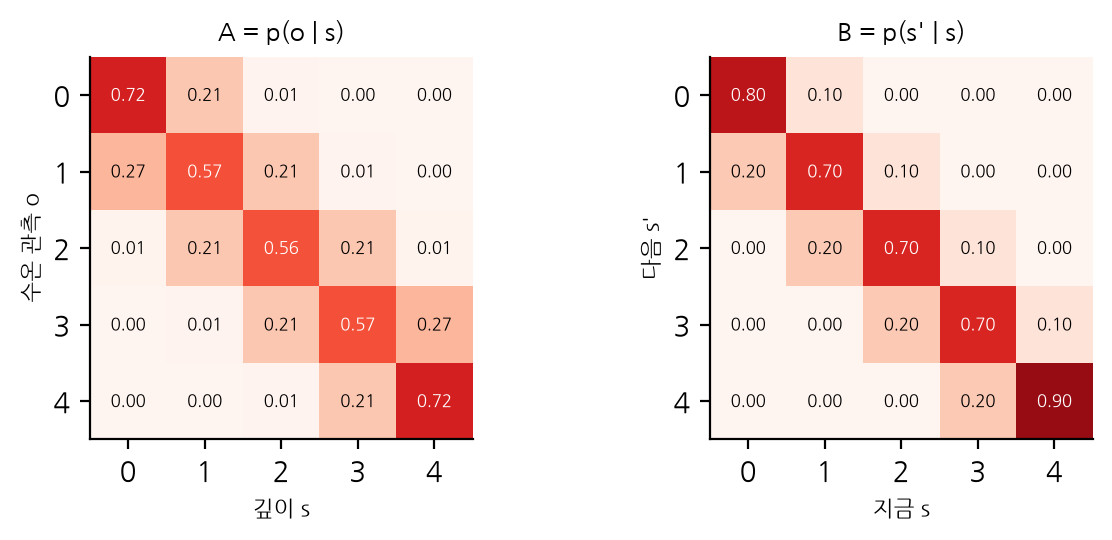

In [2]:
def makeA(sharp):
    """sharp 가 클수록 수온이 깊이를 정확히 알려 준다"""
    A = np.zeros((S, S))
    for s in range(S):
        for o in range(S):
            A[o, s] = np.exp(-sharp * (o - s) ** 2)
    return A / A.sum(axis=0)

A = makeA(1.0)
B = np.zeros((S, S))
for s in range(S):
    B[s, s] += 0.7                               # 머문다
    B[min(s + 1, S - 1), s] += 0.2               # 한 구간 아래로
    B[max(s - 1, 0), s] += 0.1                   # 한 구간 위로
D = np.ones(S) / S

print("A =\n", np.round(A, 3))
print("B =\n", np.round(B, 2))
print("열의 합  A:", A.sum(0).round(6), " B:", B.sum(0).round(6))

fig, ax = plt.subplots(1, 2, figsize=(6.4, 2.8))
for a, M, title, xl, yl in [(ax[0], A, "A = p(o | s)", "깊이 s", "수온 관측 o"),
                            (ax[1], B, "B = p(s' | s)", "지금 s", "다음 s'")]:
    a.imshow(M, cmap="Reds", vmin=0, vmax=1)
    for i in range(S):
        for j in range(S):
            a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6,
                   color="white" if M[i, j] > 0.5 else "black")
    a.set_title(title, fontsize=9); a.set_xlabel(xl, fontsize=8); a.set_ylabel(yl, fontsize=8)
    a.set_xticks(range(S)); a.set_yticks(range(S))
plt.tight_layout(); plt.show()

## 2. 한 시점의 추론

수온 구간 o = 3 을 읽었다. 정확한 사후 분포는 베이즈 정리로 A[o]·D 를 정규화한 것이다. 변분 자유 에너지 F(q) = Σ q (ln q − ln A[o] − ln D) 를 최소로 하는 q 는 softmax(ln D + ln A[o]) 이고, 이것이 정확한 사후와 같다. 그때 F 는 놀람 −ln p(o) 와 같아진다.

In [3]:
o = 3
post = A[o] * D / (A[o] @ D)
q = softmax(ln(D) + ln(A[o]))

def F(q, o, prior):
    return q @ (ln(q) - ln(A[o]) - ln(prior))

print("정확한 사후  :", np.round(post, 4))
print("softmax 해   :", np.round(q, 4))
print(f"F(softmax 해) = {F(q, o, D):.6f}")
print(f"놀람 -ln p(o) = {-np.log(A[o] @ D):.6f}")
print(f"F(균등 분포)  = {F(np.ones(S) / S, o, D):.6f}   ← 놀람보다 크다")

정확한 사후  : [1.000e-04 9.900e-03 1.970e-01 5.411e-01 2.519e-01]
softmax 해   : [1.000e-04 9.900e-03 1.970e-01 5.411e-01 2.519e-01]
F(softmax 해) = 1.557304
놀람 -ln p(o) = 1.557304
F(균등 분포)  = 3.469931   ← 놀람보다 크다


## 3. 경사 하강으로 푼다

뇌가 softmax 해를 한 번에 계산한다고 보기보다, 로그 믿음 v 를 예측 오차 ε = ln A[o] + ln D − ln s 쪽으로 조금씩 움직인다고 보는 편이 신경 회로에 가깝다. s = softmax(v) 다. 이 갱신 v ← v + κε 에서 κ 가 학습률이다. ln s = v − (상수) 이므로 v 는 (1 − κ) 배씩 목표와의 거리가 줄어든다. κ = 1 이면 한 번에 도착하고 κ > 2 면 발산한다.

κ = 0.25:  F 처음 4번 [1.987 1.692 1.612 1.582]  마지막 1.557  믿음 [0.    0.011 0.201 0.534 0.255]
κ =  1.0:  F 처음 4번 [1.557 1.557 1.557 1.557]  마지막 1.557  믿음 [0.    0.01  0.197 0.541 0.252]
κ =  1.9:  F 처음 4번 [1.634 2.179 1.611 1.798]  마지막 1.576  믿음 [0.001 0.027 0.228 0.472 0.272]
κ =  2.5:  F 처음 4번 [ 1.729 10.903  1.999 10.936]  마지막 3.182  믿음 [0. 0. 1. 0. 0.]


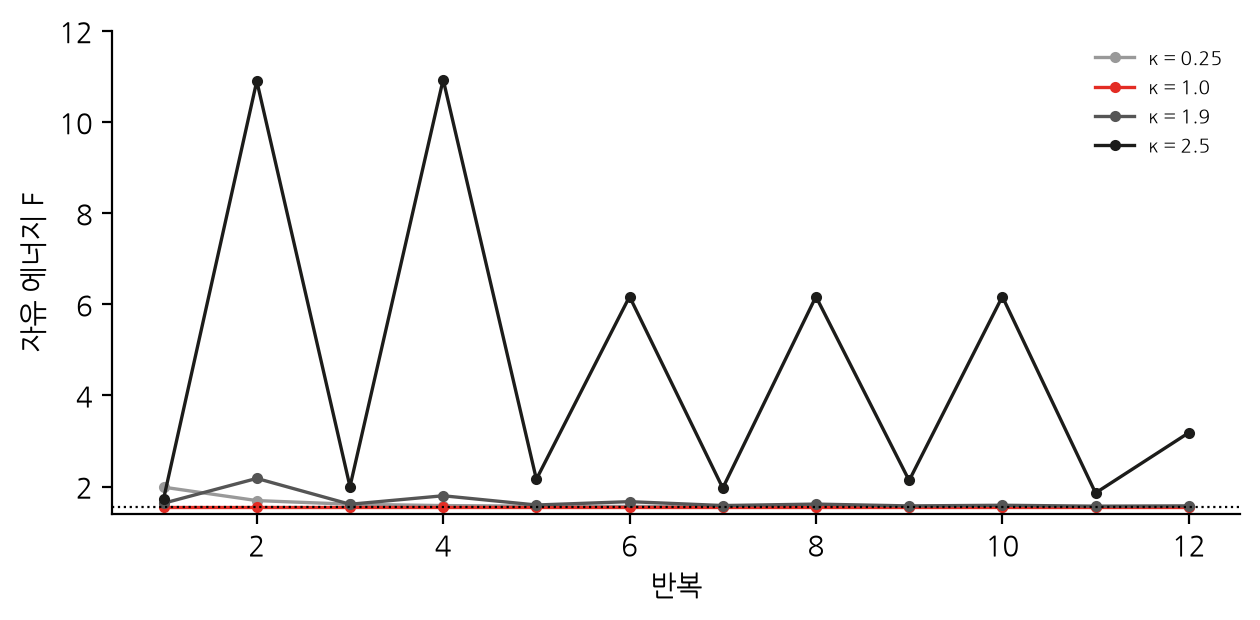

In [4]:
def descend(kappa, steps=12):
    v = ln(np.ones(S) / S)
    Fs = []
    for k in range(steps):
        s = softmax(v)
        eps = ln(A[o]) + ln(D) - ln(s)          # 예측 오차
        v = v + kappa * eps
        Fs.append(F(softmax(v), o, D))
    return np.array(Fs), softmax(v)

fig, ax = plt.subplots()
for kappa, c in [(0.25, "#999999"), (1.0, "#E32C24"), (1.9, "#555555"), (2.5, "#1C1C1A")]:
    Fs, s = descend(kappa)
    ax.plot(range(1, 13), Fs, "o-", ms=3, lw=1.2, color=c, label=f"κ = {kappa}")
    print(f"κ = {kappa:4}:  F 처음 4번 {np.round(Fs[:4], 3)}  마지막 {Fs[-1]:.3f}  믿음 {np.round(s, 3)}")
ax.axhline(-np.log(A[o] @ D), color="k", ls=":", lw=0.8)
ax.set_ylim(1.4, 12); ax.set_xlabel("반복"); ax.set_ylabel("자유 에너지 F")
ax.legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 4. 시간을 따라

Hydar 가 60 걸음 동안 해류를 따라 움직이며 수온을 읽는다. 네 가지 방법으로 깊이를 추론해 비교한다.

- 정적 추론: 매 걸음 D 만 사전으로 쓴다. B 를 무시한다.
- 필터링: 지난 믿음을 B 로 밀어 다음 걸음의 사전으로 쓴다(전방 알고리즘).
- 평활: 미래의 관측까지 써서 과거를 다시 추론한다(전방-후방 알고리즘, 사슬에서는 신뢰 전파와 같다). 정확한 기준선이다.
- 변분 메시지 전달(VMP): 걸음마다 독립인 q 를 두는 평균장 근사로, 이웃 걸음에서 ln B 로 메시지를 받는다.

참 깊이: 000000011122233334444444444444444444332222222221232222223444
수온   : 110010111012131433334444344444443444232312332311242222223343
정적    맞힌 비율 0.60
필터링   맞힌 비율 0.67
평활    맞힌 비율 0.80
VMP   맞힌 비율 0.75


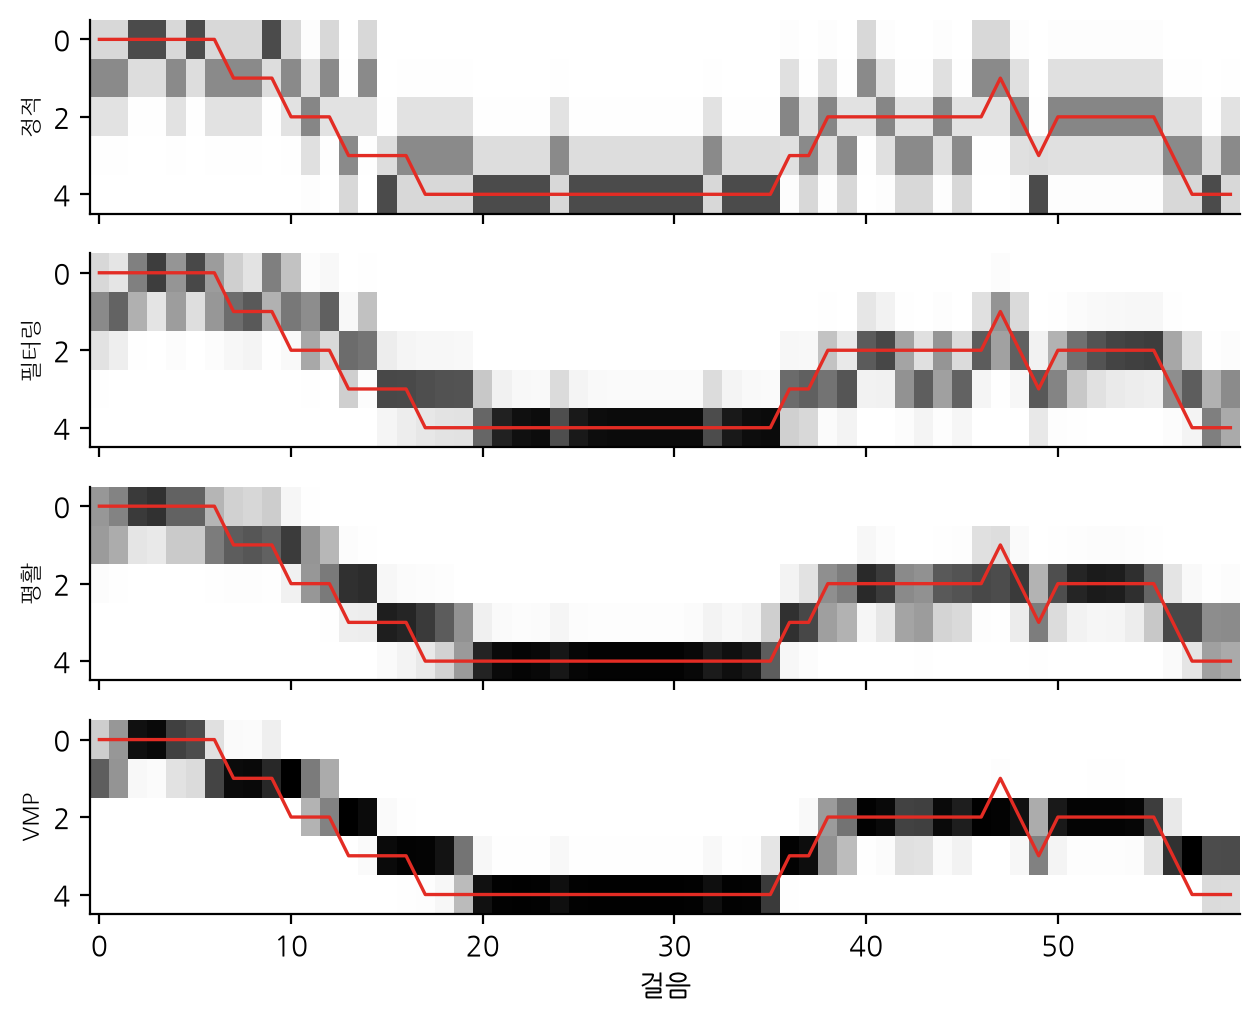

In [5]:
def simulate(T, rng, s0=0):
    s = np.zeros(T, int); obs = np.zeros(T, int); s[0] = s0
    for t in range(T):
        if t > 0:
            s[t] = rng.choice(S, p=B[:, s[t - 1]])
        obs[t] = rng.choice(S, p=A[:, s[t]])
    return s, obs

def infer_static(obs):
    return np.array([softmax(ln(D) + ln(A[x])) for x in obs]).T

def infer_filter(obs):
    Q = np.zeros((S, len(obs))); prior = D
    for t, x in enumerate(obs):
        q = A[x] * prior; q /= q.sum(); Q[:, t] = q
        prior = B @ q                            # 다음 걸음의 사전
    return Q

def infer_smooth(obs):
    T = len(obs); al = infer_filter(obs); be = np.ones((S, T))
    for t in range(T - 2, -1, -1):
        b = B.T @ (A[obs[t + 1]] * be[:, t + 1]); be[:, t] = b / b.sum()
    Q = al * be
    return Q / Q.sum(0)

def infer_vmp(obs, iters=16):
    T = len(obs); Q = np.ones((S, T)) / S
    for it in range(iters):
        for t in range(T):
            v = ln(A[obs[t]]) + (ln(D) if t == 0 else ln(B) @ Q[:, t - 1])   # 과거에서 오는 메시지
            if t < T - 1:
                v += ln(B).T @ Q[:, t + 1]                                   # 미래에서 오는 메시지
            Q[:, t] = softmax(v)
    return Q

rng = np.random.default_rng(SEED)
s_true, obs = simulate(60, rng)
print("참 깊이:", "".join(map(str, s_true)))
print("수온   :", "".join(map(str, obs)))
methods = {"정적": infer_static, "필터링": infer_filter, "평활": infer_smooth, "VMP": infer_vmp}

fig, ax = plt.subplots(4, 1, figsize=(6.4, 5.2), sharex=True)
for a, (n, f) in zip(ax, methods.items()):
    Q = f(obs)
    a.imshow(Q, aspect="auto", cmap="Greys", vmin=0, vmax=1, origin="upper")
    a.plot(s_true, color="#E32C24", lw=1.2)
    a.set_ylabel(n, fontsize=8); a.set_yticks([0, 2, 4])
    print(f"{n:4s}  맞힌 비율 {(Q.argmax(0) == s_true).mean():.2f}")
ax[-1].set_xlabel("걸음")
plt.tight_layout(); plt.show()

한 궤적만으로는 우연이 섞인다. 궤적 200개로 평균을 낸다. 맞힌 비율(가장 믿는 구간이 참인 비율), 참 상태의 평균 로그 확률(높을수록 좋고, 지나친 확신으로 틀리면 크게 깎인다), 믿음의 평균 엔트로피를 잰다.

In [6]:
rng = np.random.default_rng(7)
rows = {n: [] for n in methods}
for k in range(200):
    s_true_k, obs_k = simulate(60, rng, s0=rng.integers(S))
    for n, f in methods.items():
        Q = f(obs_k)
        rows[n].append(((Q.argmax(0) == s_true_k).mean(),
                        np.mean(ln(Q[s_true_k, np.arange(60)])),
                        np.mean(-np.sum(Q * ln(Q), 0))))
print(f"{'방법':6s}{'맞힌 비율':>10s}{'로그 확률':>10s}{'엔트로피':>10s}")
for n, r in rows.items():
    m = np.mean(r, 0)
    print(f"{n:6s}{m[0]:10.3f}{m[1]:10.3f}{m[2]:10.3f}")

방법         맞힌 비율     로그 확률      엔트로피
정적         0.643    -0.830     0.853
필터링        0.741    -0.597     0.586
평활         0.804    -0.467     0.461
VMP        0.781    -0.957     0.226


## 5. A 를 배운다

Hydar 가 A 를 모른다고 하자. A 의 각 열을 디리클레 분포로 믿고 그 계수 a 를 센다. 걸음마다 상태 믿음 q 로 a[o] ← a[o] + q 를 더한다. 관측 o 와 상태 믿음의 외적을 더하는 셈이라 「함께 일어난 것끼리 이어진다」는 헤브 학습 꼴이다. 쓰는 A 는 a 를 열마다 정규화한 값이다. 처음 계수를 세 가지로 두고, 배운 A 로 새 궤적 100개를 필터링해 맞힌 비율을 잰다.

참 A 로 필터링: 0.737
처음 계수            1      50     200    1000    3000


약한 대각        0.600   0.683   0.679   0.696   0.704


균등           0.470   0.581   0.601   0.645   0.666


뒤집힌 A        0.094   0.096   0.080   0.060   0.064


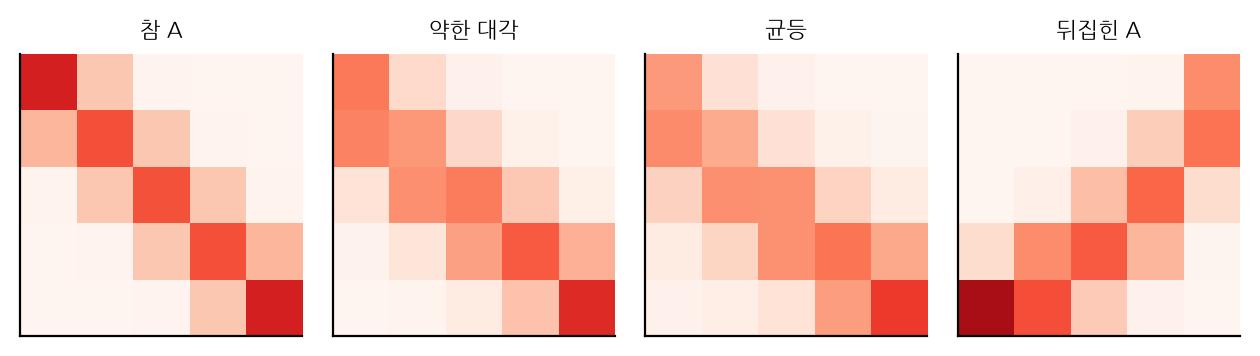

In [7]:
def learnA(a0, T, seed=3):
    rng = np.random.default_rng(seed)
    s_, o_ = simulate(T, rng, s0=2)
    a = a0.copy(); prior = D
    for t in range(T):
        Ah = a / a.sum(0)
        q = softmax(ln(prior) + ln(Ah[o_[t]]))
        a[o_[t]] += q                            # 디리클레 계수 갱신
        prior = B @ q
    return a / a.sum(0)

def heldout(Ah, n=100):
    rng = np.random.default_rng(99); acc = []
    for k in range(n):
        s_, o_ = simulate(60, rng, s0=rng.integers(S)); prior = D; hit = 0
        for t in range(60):
            q = Ah[o_[t]] * prior; q /= q.sum(); hit += q.argmax() == s_[t]; prior = B @ q
        acc.append(hit / 60)
    return np.mean(acc)

starts = {"약한 대각": makeA(0.2) * 5, "균등": np.ones((S, S)), "뒤집힌 A": makeA(1.0)[::-1] * 5}
Ts = [1, 50, 200, 1000, 3000]
print(f"참 A 로 필터링: {heldout(A):.3f}")
print(f"{'처음 계수':10s}" + "".join(f"{T:>8d}" for T in Ts))
learned = {}
for n, a0 in starts.items():
    accs = [heldout(learnA(a0, T)) for T in Ts]
    learned[n] = learnA(a0, 3000)
    print(f"{n:10s}" + "".join(f"{x:8.3f}" for x in accs))

fig, ax = plt.subplots(1, 4, figsize=(6.4, 1.9))
for a, (n, M) in zip(ax, [("참 A", A)] + list(learned.items())):
    a.imshow(M, cmap="Reds", vmin=0, vmax=1); a.set_title(n, fontsize=8)
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 6. 실패 조건

뒤집힌 A 로 시작한 Hydar 는 3000 걸음을 겪어도 거의 맞히지 못했다. 틀린 A 아래에서 추론한 상태 믿음으로 다시 A 를 세므로 틀린 짝이 스스로를 굳힌다. B 가 「아래로 흐른다」고 알려 주는 정보는 이 고리를 끊기에 약하다.

또 하나는 확률 0 이다. A 에 정확한 0 이 있을 때 모델이 「불가능하다」고 한 관측이 들어오면 베이즈 정리의 분모가 0 이 된다.

In [8]:
A0 = A.copy(); A0[A0 < 0.05] = 0; A0 /= A0.sum(0)    # 작은 확률을 0 으로 깎은 A
prior = np.array([1.0, 0, 0, 0, 0])                    # 수면에 있다고 확신
x = 4                                                  # 바닥의 수온
with np.errstate(invalid="ignore", divide="ignore"):
    naive = A0[x] * prior / (A0[x] @ prior)
print("A0[4] =", np.round(A0[x], 3), "  사전 =", prior)
print("정확한 베이즈:", naive)
print("로그 공간 + EPS:", np.round(softmax(ln(prior) + ln(A0[x])), 3))
print("D 를 균등으로 풀면:", np.round(softmax(ln(D) + ln(A0[x])), 3))

A0[4] = [0.    0.    0.    0.212 0.731]   사전 = [1. 0. 0. 0. 0.]
정확한 베이즈: [nan nan nan nan nan]
로그 공간 + EPS: [0.515 0.    0.    0.109 0.376]
D 를 균등으로 풀면: [0.    0.    0.    0.225 0.775]
